<a href="https://colab.research.google.com/github/leeknnn/viktoriiashkorubska-41/blob/master/lab_work_21/lab_work_21.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Точне значення: 0.785398
Оцінка Монте-Карло (N=1000): 0.770000
Абсолютна похибка: 0.015398
Відносна похибка: 1.96%
N =    100 | Середня абсолютна похибка: 0.035004
N =   1000 | Середня абсолютна похибка: 0.010357
N =  10000 | Середня абсолютна похибка: 0.003336
N = 100000 | Середня абсолютна похибка: 0.001061


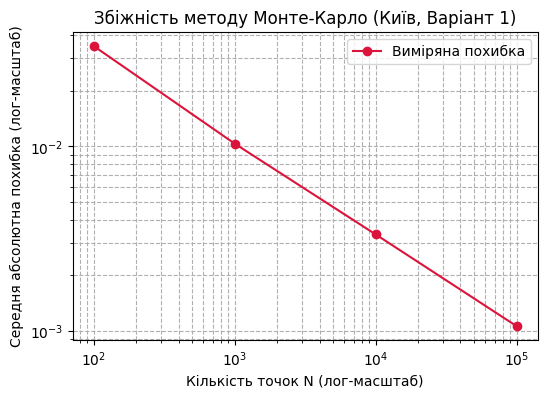

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Варіант 1: Київ (Площа чверті кола r=1 у квадраті [0,1]x[0,1])
exact_val = np.pi / 4

# Завдання 1: Оцінка при N = 1000
np.random.seed(1)
N = 1000
x = np.random.uniform(0, 1, N)
y = np.random.uniform(0, 1, N)

# Умова належності чверті кола: x^2 + y^2 <= 1
inside = (x**2 + y**2) <= 1
rect_area = 1.0  # площа квадрата [0,1]x[0,1]
mc_estimate = np.mean(inside) * rect_area

print(f"Точне значення: {exact_val:.6f}")
print(f"Оцінка Монте-Карло (N=1000): {mc_estimate:.6f}")

# Завдання 2: Абсолютна та відносна похибка
abs_err = abs(mc_estimate - exact_val)
rel_err_pct = (abs_err / exact_val) * 100
print(f"Абсолютна похибка: {abs_err:.6f}")
print(f"Відносна похибка: {rel_err_pct:.2f}%")

# Завдання 3: Збіжність за кількістю випробувань
N_vals = [100, 1_000, 10_000, 100_000]
mean_errors = []

np.random.seed(1)
for n_pts in N_vals:
    errors = []
    for _ in range(200):
        x_pts = np.random.uniform(0, 1, n_pts)
        y_pts = np.random.uniform(0, 1, n_pts)
        est = np.mean((x_pts**2 + y_pts**2) <= 1) * rect_area
        errors.append(abs(est - exact_val))
    avg_err = np.mean(errors)
    mean_errors.append(avg_err)
    print(f"N = {n_pts:6d} | Середня абсолютна похибка: {avg_err:.6f}")

# Завдання 4: Графік залежності похибки від N
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(N_vals, mean_errors, 'o-', color='crimson', label='Виміряна похибка')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Кількість точок N (лог-масштаб)')
ax.set_ylabel('Середня абсолютна похибка (лог-масштаб)')
ax.set_title('Збіжність методу Монте-Карло (Київ, Варіант 1)')
ax.grid(True, which="both", ls="--")
ax.legend()
plt.show()

## Відповіді на контрольні питання

1. **Чому оцінка методом Монте-Карло — це вибіркове середнє, і який результат гарантує її наближення до точного значення?**
   - Оцінка Монте-Карло обчислюється як середня частка успішних точок (або середнє значення функції в випадкових точках), тобто є класичним вибірковим середнім випадкової величини $\bar{X}_N = \frac{1}{N} \sum_{i=1}^N Y_i$. **Закон великих чисел (ЗВЧ)** математично гарантує, що при $N \to \infty$ це вибіркове середнє неминуче прямує за ймовірністю до математичного сподівання генеральної сукупності (точного значення площі або інтеграла).

2. **Чому вчетверо більша кількість випробувань дає лише вдвічі меншу похибку?**
   - Згідно з **Центральною граничною теоремою (ЦГТ)**, стандартна похибка вибіркового середнього визначається формулою $\text{SE} = \frac{\sigma}{\sqrt{N}}$, де $\sigma$ — стандартне відхилення окремого випробування, а $N$ — кількість точок. Через наявність квадратного кореню у знаменнику, щоб зменшити похибку в 2 рази, необхідно збільшити розмір вибірки $N$ у $2^2 = 4$ рази.

3. **Чому частку точок для варіанта «площа» потрібно множити на площу прямокутника-охоплення?**
   - Метод Монте-Карло обчислює геометричну ймовірність потрапляння точки в досліджувану фігуру, тобто відношення $P = \frac{S_{\text{фігури}}}{S_{\text{прямокутника}}}$. Оцінюючи цю частку за допомогою генерації випадкових точок ($\hat{P} \approx P$), для отримання безпосередньо площі фігури $S_{\text{фігури}}$ необхідно помножити згенеровану частку $\hat{P}$ на повну відому площу прямокутника $S_{\text{прямокутника}}$.

4. **Чому саме .min(axis=1) або .max(axis=1) дає масив результатів окремо для кожного випробування?**
   - При використанні двовимірного масиву розміру $(N, k)$ кожен рядок представляє один окремий експеримент із $k$ кидків. Застосування параметрa `axis=1` вказує функції згортати дані вздовж стовпчиків у межах кожного рядка окремо, повертаючи вектор довжиною $N$ із мінімумами/максимумами для кожної симуляції, а не одне число по всій матриці.